# 02 - Modeling Churn Prediction

Objectif : construire un pipeline machine learning complet pour predire le churn client.

Approche retenue :
- `Logistic Regression` pour l'interpretation des facteurs qui augmentent ou reduisent le churn
- `Random Forest` comme modele final de prediction
- `SMOTE` pour reequilibrer la classe minoritaire sur le jeu d'entrainement

Tous les artefacts machine learning sont sauvegardes dans `machine_learning/`.

In [7]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

## Chemins du projet

In [8]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
ML_DIR = PROJECT_ROOT / "machine_learning"
MODEL_DIR = ML_DIR / "models"
FIG_DIR = ML_DIR / "figures"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Machine learning dir:", ML_DIR)

Project root: c:\Users\bourbia\Desktop\projet_pythonn
Machine learning dir: c:\Users\bourbia\Desktop\projet_pythonn\machine_learning


## Style des figures ML

In [9]:
sns.set_theme(style="whitegrid", context="talk")
BG = "#f7efe1"
PANEL = "#fffaf0"
INK = "#17211b"
MUTED = "#687466"
MOSS = "#304c3d"
SAGE = "#9caf88"
CORAL = "#d45d4c"
AMBER = "#d99a3d"
TEAL = "#2f7f7a"
GRID = "#dfd4bf"

mpl.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": PANEL,
    "savefig.facecolor": BG,
    "axes.edgecolor": "#d8cdb9",
    "axes.labelcolor": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "text.color": INK,
    "font.family": "serif",
    "font.serif": ["Georgia", "Times New Roman", "DejaVu Serif"],
})


def polish(ax, grid_axis="y"):
    ax.grid(True, axis=grid_axis, color=GRID, linewidth=0.9, alpha=0.85)
    ax.grid(False, axis="x" if grid_axis == "y" else "y")
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_color("#d8cdb9")
    ax.spines["bottom"].set_color("#d8cdb9")


def save(fig, filename):
    fig.savefig(FIG_DIR / filename, dpi=220, bbox_inches="tight")
    plt.close(fig)

## Chargement du dataset nettoye

In [10]:
df = pd.read_csv(DATA_DIR / "cleaned_dataset.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnBinary
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


## Preparation des variables

In [11]:
X = df.drop(columns=["customerID", "Churn", "ChurnBinary"])
y = df["ChurnBinary"]

num_cols = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Train churn rate:", round(y_train.mean() * 100, 2), "%")
print("Test churn rate:", round(y_test.mean() * 100, 2), "%")

Train shape: (5634, 19)
Test shape: (1409, 19)
Train churn rate: 26.54 %
Test churn rate: 26.54 %


## Preprocessing et SMOTE

In [12]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ]
)

smote = SMOTE(random_state=42)

X_train_prepared = preprocessor.fit_transform(X_train)
X_train_smote, y_train_smote = smote.fit_resample(X_train_prepared, y_train)

print("Avant SMOTE:")
print(y_train.value_counts().sort_index())
print("\nApres SMOTE:")
print(pd.Series(y_train_smote).value_counts().sort_index())

Avant SMOTE:
ChurnBinary
0    4139
1    1495
Name: count, dtype: int64

Apres SMOTE:
ChurnBinary
0    4139
1    4139
Name: count, dtype: int64


## Visualisation du reequilibrage

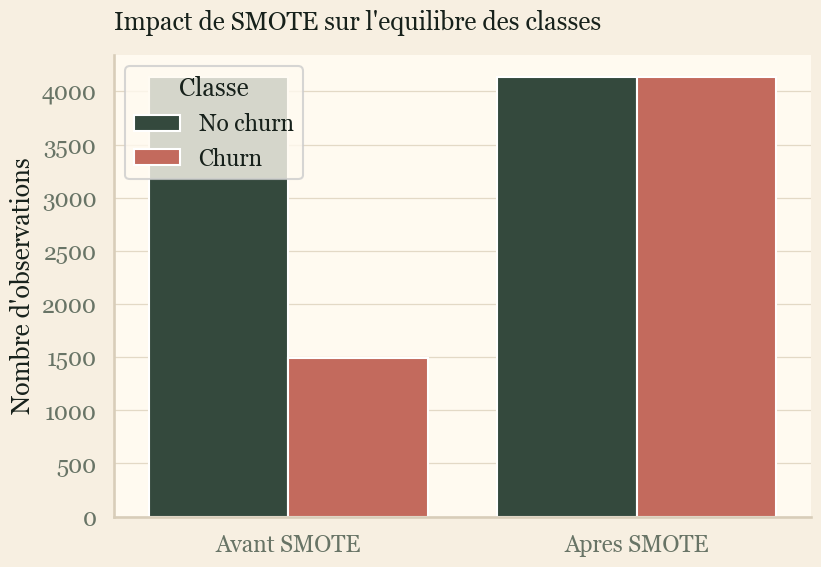

In [13]:
before_counts = y_train.value_counts().sort_index()
after_counts = pd.Series(y_train_smote).value_counts().sort_index()
plot_df = pd.DataFrame({
    "Classe": ["No churn", "Churn", "No churn", "Churn"],
    "Nombre": [before_counts[0], before_counts[1], after_counts[0], after_counts[1]],
    "Etat": ["Avant SMOTE", "Avant SMOTE", "Apres SMOTE", "Apres SMOTE"],
})

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=plot_df, x="Etat", y="Nombre", hue="Classe", palette=[MOSS, CORAL], ax=ax)
ax.set_title("Impact de SMOTE sur l'equilibre des classes", loc="left", pad=18)
ax.set_xlabel("")
ax.set_ylabel("Nombre d'observations")
polish(ax)
plt.show()
save(fig, "class_balance_before_after_smote.png")

## Pipelines de modeles

In [14]:
logistic_model = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", LogisticRegression(max_iter=2000, random_state=42)),
])

rf_model = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(
        n_estimators=350,
        max_depth=9,
        min_samples_leaf=8,
        random_state=42,
        n_jobs=1,
    )),
])

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
}

## Entrainement des modeles

In [15]:
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained")

Logistic Regression trained
Random Forest trained


## Evaluation comparative

In [16]:
results = []
predictions = {}
probabilities = {}
reports = {}

for name, model in models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    predictions[name] = pred
    probabilities[name] = proba
    reports[name] = classification_report(y_test, pred, target_names=["No churn", "Churn"], output_dict=True)
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
        "average_precision": average_precision_score(y_test, proba),
    })

results_df = pd.DataFrame(results).sort_values("f1", ascending=False)
results_df.round(4)

,model,accuracy,precision,recall,f1,roc_auc,average_precision
1,Random Forest,0.7651,0.5436,0.7166,0.6182,0.8388,0.6336
0,Logistic Regression,0.7374,0.5034,0.7941,0.6162,0.8402,0.6282


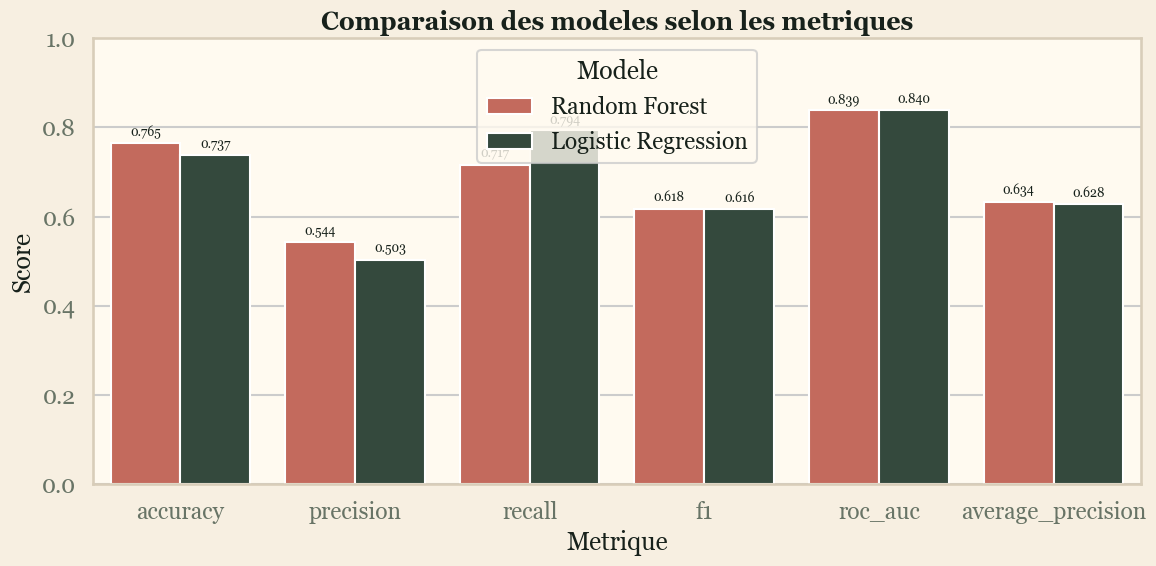

In [18]:
metrics_long = results_df.melt(id_vars="model", var_name="metric", value_name="score")

plt.figure(figsize=(12, 6))
sns.barplot(
    data=metrics_long,
    x="metric",
    y="score",
    hue="model",
    palette=["#d45d4c", "#304c3d"]
)

plt.title("Comparaison des modeles selon les metriques", fontweight="bold")
plt.xlabel("Metrique")
plt.ylabel("Score")
plt.ylim(0, 1)

for container in plt.gca().containers:
    plt.gca().bar_label(container, fmt="%.3f", padding=3, fontsize=9)

plt.legend(title="Modele")
plt.tight_layout()
save(fig, "model_metrics_comparison_barplot.png")
plt.show()


## Matrices de confusion

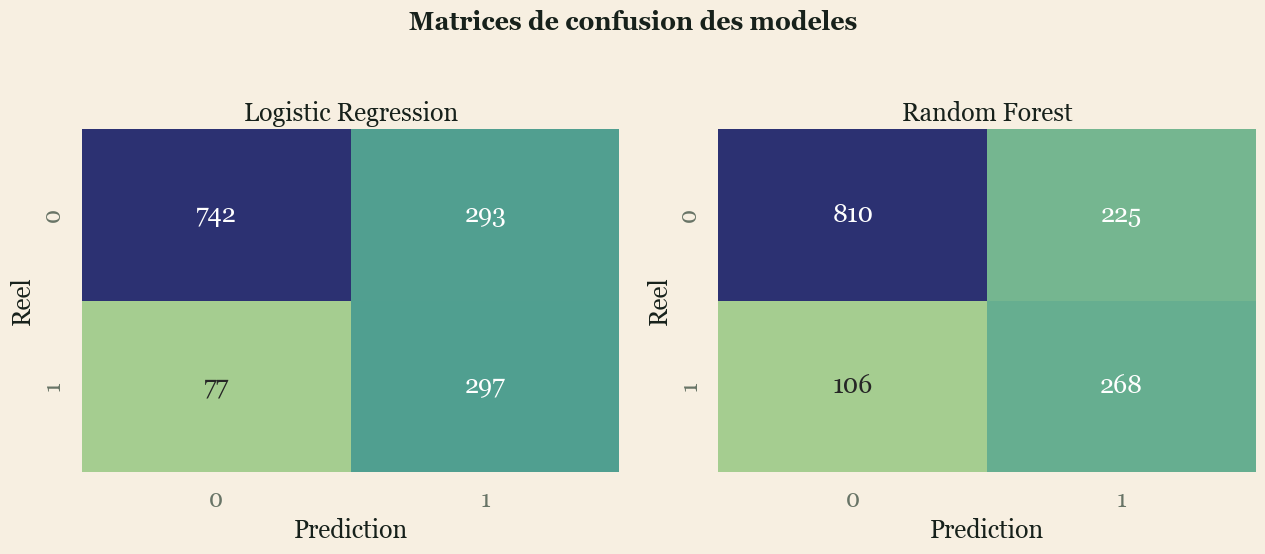

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="crest", cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Prediction")
    ax.set_ylabel("Reel")
plt.suptitle("Matrices de confusion des modeles", y=1.02, fontsize=18, fontweight="bold")
plt.tight_layout()
plt.show()
save(fig, "confusion_matrices.png")

## Courbes ROC

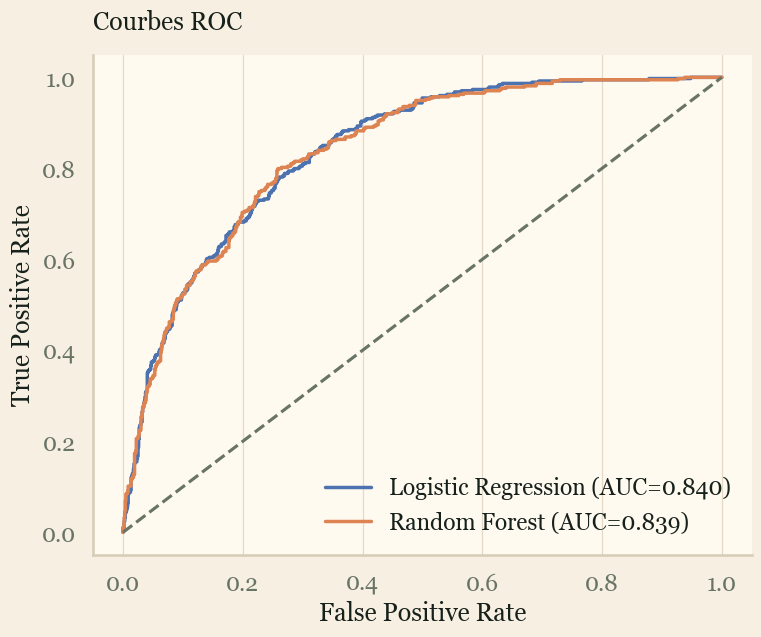

In [20]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))
for name, proba in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    ax.plot(fpr, tpr, linewidth=2.5, label=f"{name} (AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color=MUTED)
ax.set_title("Courbes ROC", loc="left", pad=18)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(frameon=False)
polish(ax, grid_axis="both")
plt.show()
save(fig, "roc_curves.png")

## Courbes Precision-Recall

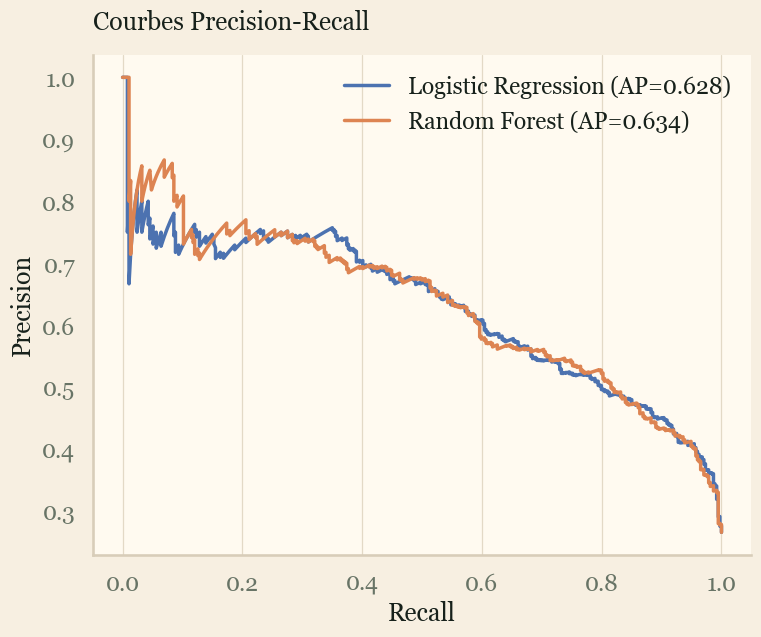

In [21]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))
for name, proba in probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    ax.plot(recall, precision, linewidth=2.5, label=f"{name} (AP={ap:.3f})")
ax.set_title("Courbes Precision-Recall", loc="left", pad=18)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend(frameon=False)
polish(ax, grid_axis="both")
plt.show()
save(fig, "precision_recall_curves.png")

## Importance des variables - Random Forest

In [22]:
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()
feature_names = [name.replace("num__", "").replace("cat__", "") for name in feature_names]

rf_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_model.named_steps["model"].feature_importances_,
}).sort_values("importance", ascending=False)
rf_importance.to_csv(ML_DIR / "random_forest_feature_importance.csv", index=False)
rf_importance.head(15)

,feature,importance
36,Contract_Month-to-month,0.153428
18,OnlineSecurity_No,0.089635
1,tenure,0.089319
43,PaymentMethod_Electronic check,0.075679
38,Contract_Two year,0.069171
27,TechSupport_No,0.064376
3,TotalCharges,0.053742
16,InternetService_Fiber optic,0.043199
2,MonthlyCharges,0.034294
40,PaperlessBilling_Yes,0.025699


C:\Users\bourbia\AppData\Local\Temp\ipykernel_14192\1649438572.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_rf, x="importance", y="feature", palette="crest", ax=ax)


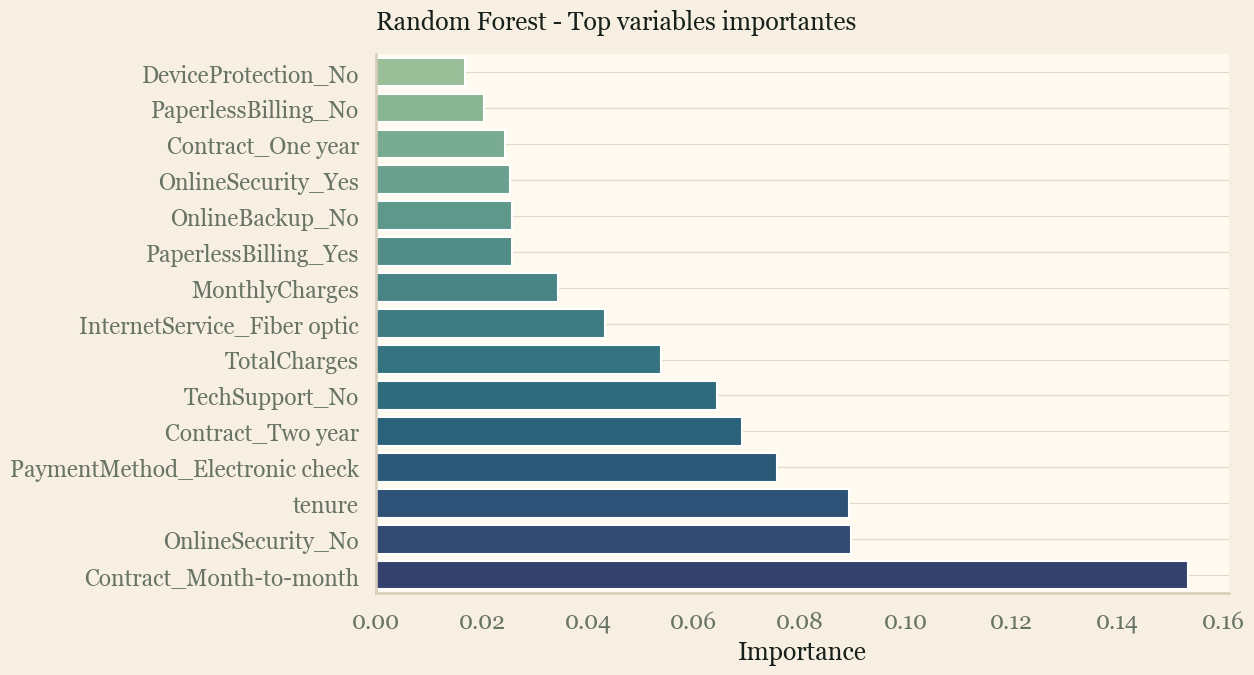

In [23]:
fig, ax = plt.subplots(figsize=(11, 7))
top_rf = rf_importance.head(15).sort_values("importance")
sns.barplot(data=top_rf, x="importance", y="feature", palette="crest", ax=ax)
ax.set_title("Random Forest - Top variables importantes", loc="left", pad=18)
ax.set_xlabel("Importance")
ax.set_ylabel("")
polish(ax)
plt.show()
save(fig, "random_forest_feature_importance.png")

## Coefficients de la Logistic Regression

In [24]:
log_coef = pd.DataFrame({
    "feature": feature_names,
    "coefficient": logistic_model.named_steps["model"].coef_[0],
})
log_coef["abs_coefficient"] = log_coef["coefficient"].abs()
log_coef = log_coef.sort_values("abs_coefficient", ascending=False)
log_coef.to_csv(ML_DIR / "logistic_regression_coefficients.csv", index=False)
log_coef.head(15)

,feature,coefficient,abs_coefficient
1,tenure,-1.364046,1.364046
38,Contract_Two year,-0.765113,0.765113
3,TotalCharges,0.740664,0.740664
2,MonthlyCharges,-0.714298,0.714298
36,Contract_Month-to-month,0.675595,0.675595
16,InternetService_Fiber optic,0.667433,0.667433
15,InternetService_DSL,-0.616855,0.616855
39,PaperlessBilling_No,-0.328608,0.328608
43,PaymentMethod_Electronic check,0.294103,0.294103
9,Dependents_Yes,-0.291027,0.291027


C:\Users\bourbia\AppData\Local\Temp\ipykernel_14192\2570519213.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_log, x="coefficient", y="feature", palette=colors, ax=ax)


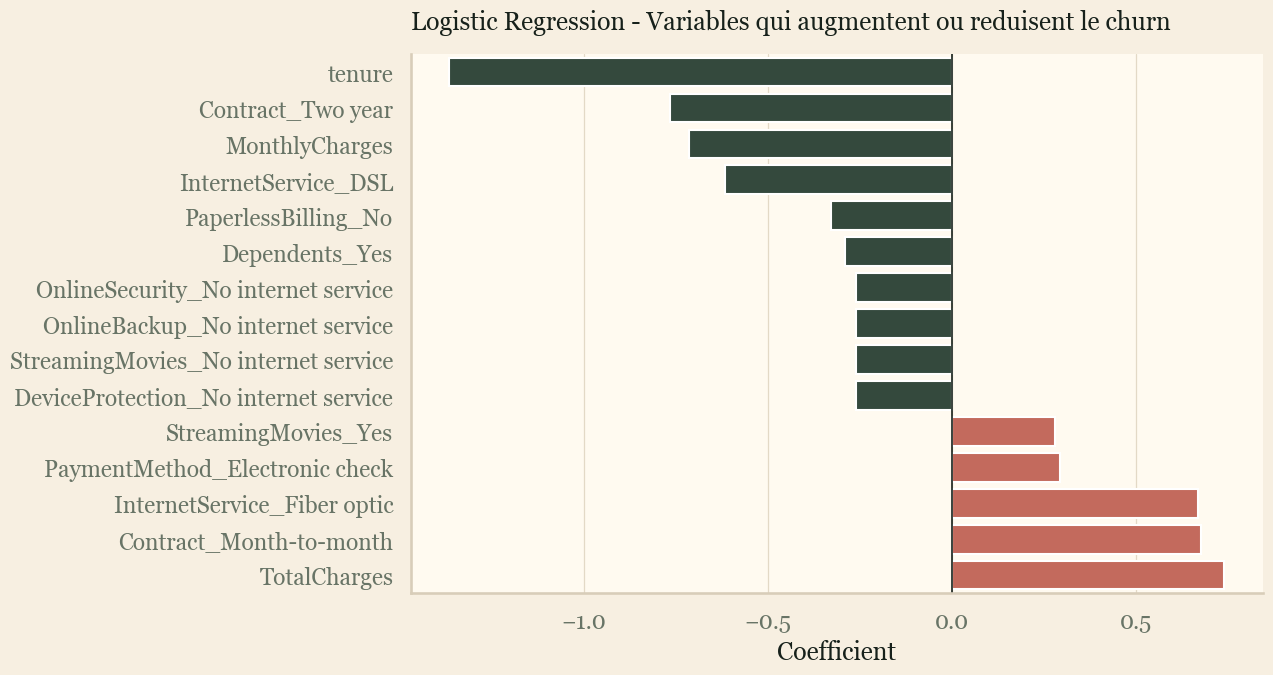

In [25]:
fig, ax = plt.subplots(figsize=(11, 7))
top_log = log_coef.head(15).copy().sort_values("coefficient")
colors = [MOSS if v < 0 else CORAL for v in top_log["coefficient"]]
sns.barplot(data=top_log, x="coefficient", y="feature", palette=colors, ax=ax)
ax.axvline(0, color=INK, linewidth=1.2)
ax.set_title("Logistic Regression - Variables qui augmentent ou reduisent le churn", loc="left", pad=18)
ax.set_xlabel("Coefficient")
ax.set_ylabel("")
polish(ax, grid_axis="x")
plt.show()
save(fig, "logistic_regression_coefficients.png")

## Sauvegarde des modeles

In [26]:
joblib.dump(rf_model, MODEL_DIR / "random_forest_churn_model.pkl")
joblib.dump(logistic_model, MODEL_DIR / "logistic_regression_churn_model.pkl")
print("Models saved to:", MODEL_DIR)

Models saved to: c:\Users\bourbia\Desktop\projet_pythonn\machine_learning\models
